<a href="https://colab.research.google.com/github/steffanymarcellia046/ProjectETSMachineLearning/blob/main/Final_Code_EAS_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install prophet openpyxl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd

try:
    df = pd.read_excel('Coffee Shop Sales.xlsx', engine='openpyxl')
    print('Dataset berhasil dimuat!')
    display(df.head())
except Exception as e:
    print('Gagal membaca dataset:', e)

Dataset berhasil dimuat!


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [ ]:
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi data:")
df.info()

print("\nJumlah missing value:")
print(df.isnull().sum())

Ukuran dataset: (149116, 11)

Nama kolom:
['transaction_id', 'transaction_date', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']

Lima baris pertama:


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg



Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  object        
 9   product_type      149116 non-null  object        
 10  product_detail    149116 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(4), object(5)
memory usage: 12.5+ MB

Jumlah missing value:
transaction_id      0
transaction_date    0
transact

Filter data

In [ ]:
# Mengubah tanggal ke format datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"],
    errors="coerce"
)

# Mengubah kuantitas menjadi numerik
df["transaction_qty"] = pd.to_numeric(
    df["transaction_qty"],
    errors="coerce"
)

# Menghapus baris yang tanggal atau kuantitasnya tidak valid
df = df.dropna(
    subset=["transaction_date", "transaction_qty", "store_location"]
)

# Memastikan kuantitas tidak negatif
df = df[df["transaction_qty"] >= 0]

# Memilih satu lokasi
df_lokasi = df[
    df["store_location"] == "Hell's Kitchen"
].copy()

print("Jumlah baris setelah filter:", len(df_lokasi))
print("Tanggal awal:", df_lokasi["transaction_date"].min())
print("Tanggal akhir:", df_lokasi["transaction_date"].max())

display(df_lokasi.head())

Jumlah baris setelah filter: 50735
Tanggal awal: 2023-01-01 00:00:00
Tanggal akhir: 2023-06-30 00:00:00


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
17,18,2023-01-01,08:00:18,1,8,Hell's Kitchen,42,2.50,Tea,Brewed herbal tea,Lemon Grass Rg
18,19,2023-01-01,08:00:39,2,8,Hell's Kitchen,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
19,20,2023-01-01,08:11:45,1,8,Hell's Kitchen,61,4.75,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg
20,21,2023-01-01,08:17:27,2,8,Hell's Kitchen,33,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg
23,24,2023-01-01,08:29:38,1,8,Hell's Kitchen,56,2.55,Tea,Brewed Chai tea,Spicy Eye Opener Chai Rg


Penjualan per hari

In [ ]:
# Menjumlahkan kuantitas penjualan setiap hari
data_harian = (
    df_lokasi
    .groupby("transaction_date")["transaction_qty"]
    .sum()
    .reset_index()
)

# Menyesuaikan nama kolom untuk Prophet
data_harian = data_harian.rename(
    columns={
        "transaction_date": "ds",
        "transaction_qty": "y"
    }
)

# Membuat rentang tanggal harian yang lengkap
rentang_tanggal = pd.date_range(
    start=data_harian["ds"].min(),
    end=data_harian["ds"].max(),
    freq="D"
)

data_harian = (
    data_harian
    .set_index("ds")
    .reindex(rentang_tanggal, fill_value=0)
    .rename_axis("ds")
    .reset_index()
)

print("Jumlah data harian:", len(data_harian))
print("\nData harian:")
display(data_harian.head(10))

print("\nStatistik deskriptif:")
display(data_harian["y"].describe())

Jumlah data harian: 181

Data harian:


,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235
5,2023-01-06,256
6,2023-01-07,323
7,2023-01-08,277
8,2023-01-09,272
9,2023-01-10,273



Statistik deskriptif:


,y
count,181.000000
mean,396.337017
std,129.535462
min,195.000000
25%,290.000000
50%,363.000000
75%,483.000000
max,769.000000


EDA

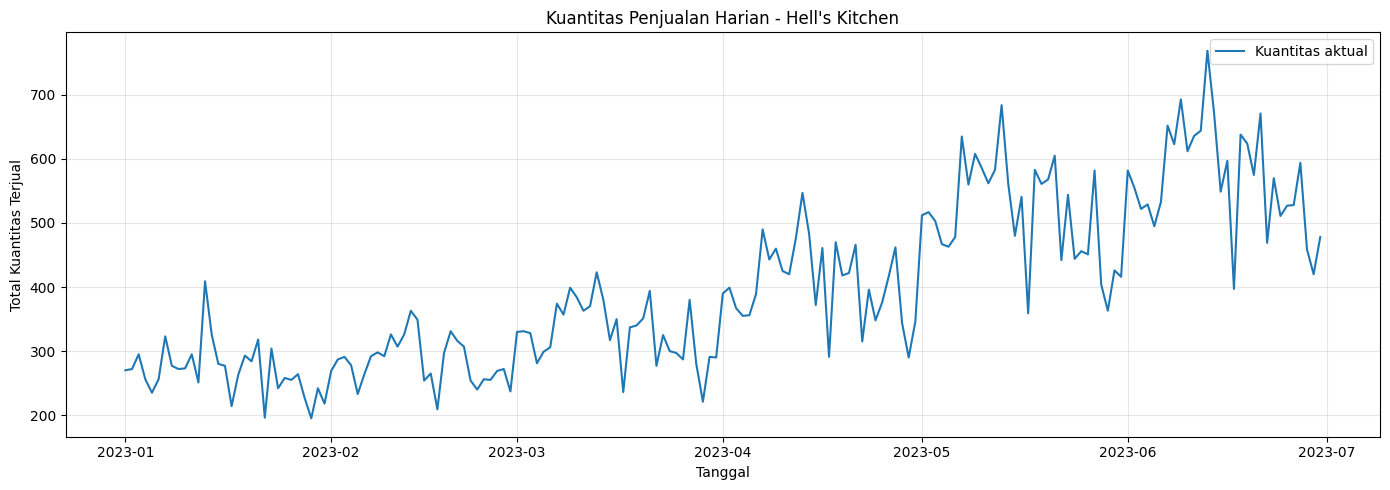

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    data_harian["ds"],
    data_harian["y"],
    label="Kuantitas aktual"
)

plt.title("Kuantitas Penjualan Harian - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Total Kuantitas Terjual")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Pola penjualan berdasarkan hari

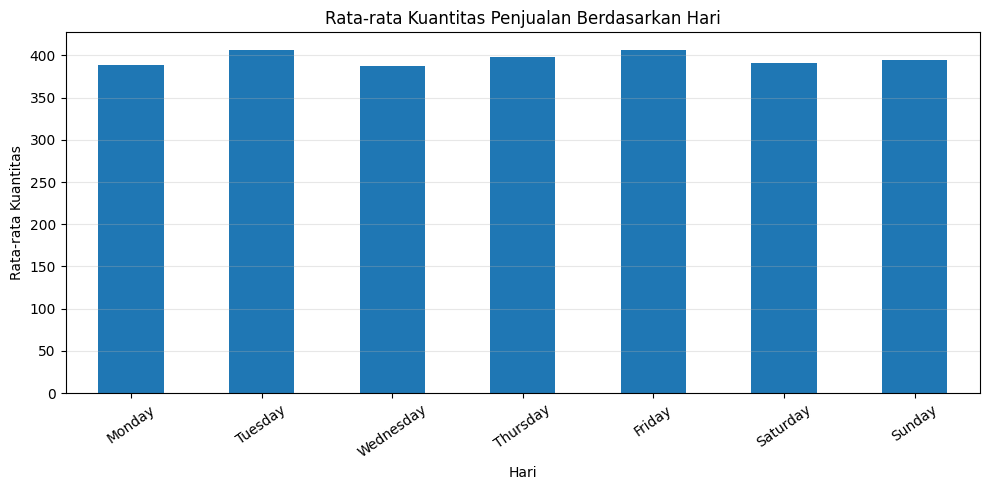

In [ ]:
data_harian["nama_hari"] = (
    data_harian["ds"].dt.day_name()
)

urutan_hari = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

rata_hari = (
    data_harian
    .groupby("nama_hari")["y"]
    .mean()
    .reindex(urutan_hari)
)

plt.figure(figsize=(10, 5))
rata_hari.plot(kind="bar")

plt.title("Rata-rata Kuantitas Penjualan Berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Rata-rata Kuantitas")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Pemisahan data training dan testing

In [ ]:
# Pastikan urutan tanggal sudah benar
data_harian = data_harian.sort_values("ds").reset_index(drop=True)

# Pembagian berdasarkan waktu
split_index = int(len(data_harian) * 0.80)

train = data_harian.iloc[:split_index][["ds", "y"]].copy()
test = data_harian.iloc[split_index:][["ds", "y"]].copy()

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))

print("\nPeriode training:")
print(train["ds"].min(), "sampai", train["ds"].max())

print("\nPeriode testing:")
print(test["ds"].min(), "sampai", test["ds"].max())

Jumlah data training: 144
Jumlah data testing: 37

Periode training:
2023-01-01 00:00:00 sampai 2023-05-24 00:00:00

Periode testing:
2023-05-25 00:00:00 sampai 2023-06-30 00:00:00


Fungsi evaluasi

In [ ]:
import pandas as pd
import numpy as np
from prophet import Prophet

def evaluasi_model(aktual, prediksi):
    aktual = np.asarray(aktual, dtype=float)
    prediksi = np.maximum(
        np.asarray(prediksi, dtype=float), 0
    )

    error = aktual - prediksi

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    # MAPE tidak terdefinisi jika nilai aktual = 0
    mask = aktual != 0
    mape = (
        np.mean(np.abs(error[mask] / aktual[mask])) * 100
        if mask.any() else np.nan
    )

    penyebut = np.abs(aktual) + np.abs(prediksi)
    smape_per_baris = np.divide(
        2 * np.abs(error),
        penyebut,
        out=np.zeros_like(penyebut, dtype=float),
        where=penyebut != 0
    )
    smape = np.mean(smape_per_baris) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "SMAPE (%)": smape
    }

Latih prophet baseline dan prophet jittering

In [ ]:
# Salin dan rapikan data
train_asli = train[["ds", "y"]].copy()
validasi = test[["ds", "y"]].copy()

train_asli["ds"] = pd.to_datetime(train_asli["ds"])
validasi["ds"] = pd.to_datetime(validasi["ds"])

train_asli = train_asli.sort_values("ds").reset_index(drop=True)
validasi = validasi.sort_values("ds").reset_index(drop=True)

# MODEL A: Prophet dengan data training asli
model_baseline = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_baseline.fit(train_asli)

pred_baseline = model_baseline.predict(
    validasi[["ds"]]
)["yhat"].to_numpy()

# MODEL B: Prophet dengan noise injection pada training
rng = np.random.default_rng(42)

# Besar noise: 2% dari simpangan baku target training
besar_noise = 0.02 * train_asli["y"].std()

train_jitter = train_asli.copy()
noise = rng.normal(
    loc=0,
    scale=besar_noise,
    size=len(train_jitter)
)

# Penjualan tidak boleh negatif
train_jitter["y"] = np.maximum(
    train_jitter["y"].to_numpy() + noise,
    0
)

model_jitter = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_jitter.fit(train_jitter)

pred_jitter = model_jitter.predict(
    validasi[["ds"]]
)["yhat"].to_numpy()

# Evaluasi kedua model pada data validasi yang sama
hasil_perbandingan = pd.DataFrame([
    {
        "Model": "Prophet Baseline",
        **evaluasi_model(validasi["y"], pred_baseline)
    },
    {
        "Model": "Prophet + Jittering",
        **evaluasi_model(validasi["y"], pred_jitter)
    }
])

display(hasil_perbandingan.round(4))

,Model,MAE,RMSE,MAPE (%),SMAPE (%)
0,Prophet Baseline,87.2320,104.5342,17.6828,15.9248
1,Prophet + Jittering,87.8597,105.4581,17.8453,16.0231


Hasil prophet baseline & prophet jittering

In [ ]:
metrik = ["MAE", "RMSE", "MAPE (%)", "SMAPE (%)"]

hasil = hasil_perbandingan.set_index("Model")

print("Perbandingan perubahan nilai error:")
for kolom in metrik:
    baseline = hasil.loc["Prophet Baseline", kolom]
    jitter = hasil.loc["Prophet + Jittering", kolom]

    perubahan = jitter - baseline

    print(
        f"{kolom}: baseline={baseline:.4f}, "
        f"jitter={jitter:.4f}, "
        f"perubahan={perubahan:+.4f}"
    )

Perbandingan perubahan nilai error:
MAE: baseline=87.2320, jitter=87.8597, perubahan=+0.6277
RMSE: baseline=104.5342, jitter=105.4581, perubahan=+0.9239
MAPE (%): baseline=17.6828, jitter=17.8453, perubahan=+0.1625
SMAPE (%): baseline=15.9248, jitter=16.0231, perubahan=+0.0983


Siapkan library dan data penjualan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet

# Ubah tanggal menjadi format datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"]
)

# Pilih lokasi Hell's Kitchen
df = df[
    df["store_location"] == "Hell's Kitchen"
].copy()

# Agregasi jumlah penjualan per hari
data_harian = (
    df.groupby("transaction_date")["transaction_qty"]
    .sum()
    .reset_index()
)

# Sesuaikan nama kolom untuk Prophet
data_harian = data_harian.rename(
    columns={
        "transaction_date": "ds",
        "transaction_qty": "y"
    }
)

# Pastikan tanggal berurutan
data_harian = data_harian.sort_values(
    "ds"
).reset_index(drop=True)

# Tampilkan data
display(data_harian.head())
print("Jumlah data harian:", len(data_harian))
print("Periode:", data_harian["ds"].min(),
      "sampai", data_harian["ds"].max())

,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235


Jumlah data harian: 181
Periode: 2023-01-01 00:00:00 sampai 2023-06-30 00:00:00


Pembagian data training dan testing

In [ ]:
data_harian = (
    data_harian.sort_values("ds")
    .reset_index(drop=True)
)

split_index = int(len(data_harian) * 0.80)

train = data_harian.iloc[:split_index][
    ["ds", "y"]
].copy()

test = data_harian.iloc[split_index:][
    ["ds", "y"]
].copy()

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))

print(
    "\nPeriode training:",
    train["ds"].min(), "sampai", train["ds"].max()
)

print(
    "Periode testing:",
    test["ds"].min(), "sampai", test["ds"].max()
)

Jumlah data training: 144
Jumlah data testing: 37

Periode training: 2023-01-01 00:00:00 sampai 2023-05-24 00:00:00
Periode testing: 2023-05-25 00:00:00 sampai 2023-06-30 00:00:00


Melatih Prophet Baseline

In [ ]:
model_baseline = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_baseline.fit(train)

# Prediksi pada tanggal testing
forecast_baseline = model_baseline.predict(
    test[["ds"]]
)

prediksi_baseline = np.maximum(
    forecast_baseline["yhat"].to_numpy(),
    0
)

print("Model Prophet baseline selesai dilatih.")

Model Prophet baseline selesai dilatih.


Visualisasi hasil prediksi

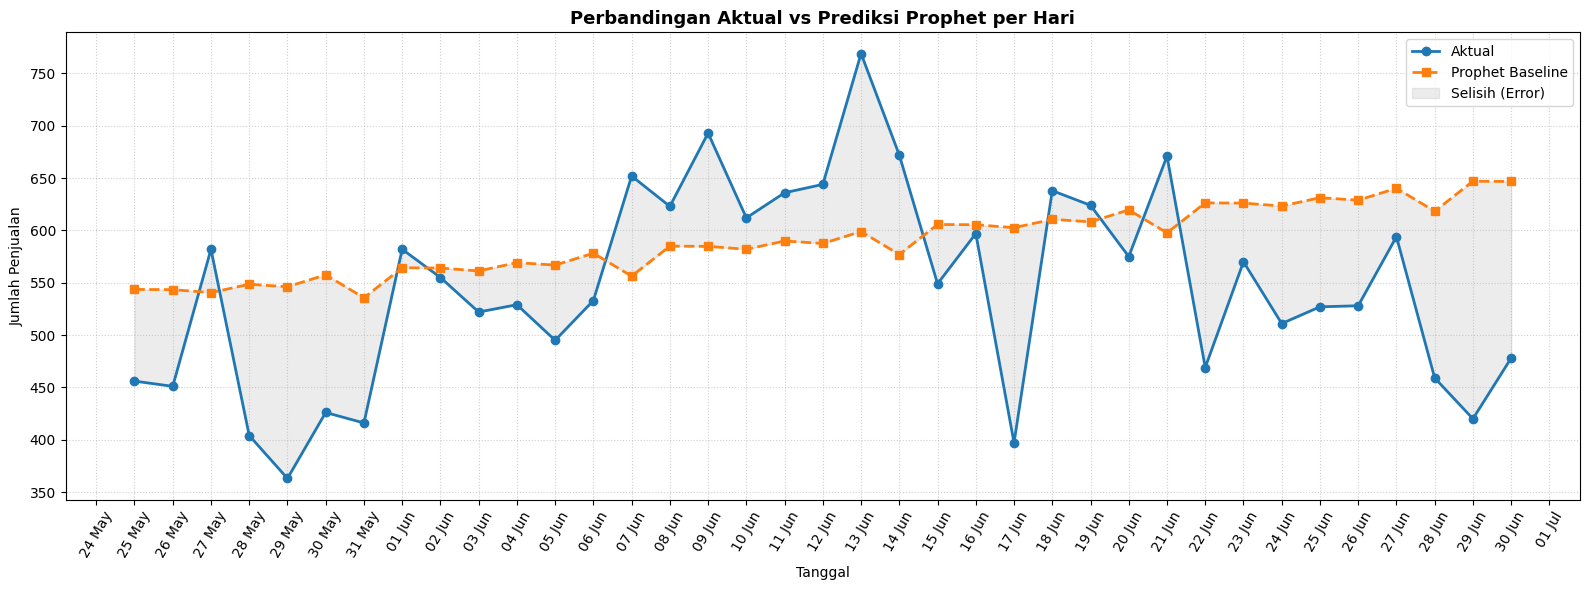

In [ ]:
import matplotlib.dates as mdates

plt.figure(figsize=(16, 6))

# Plot Aktual dengan marker jelas
plt.plot(
    test["ds"],
    test["y"],
    label="Aktual",
    marker="o",
    linewidth=2,
    color="#1f77b4"
)

# Plot Prediksi Prophet dengan marker & garis putus-putus agar mudah dibedakan
plt.plot(
    test["ds"],
    prediksi_baseline,
    label="Prophet Baseline",
    marker="s",
    linestyle="--",
    linewidth=2,
    color="#ff7f0e"
)

# Arsiran selisih antara Aktual dan Prediksi per hari
plt.fill_between(
    test["ds"],
    test["y"],
    prediksi_baseline,
    color="gray",
    alpha=0.15,
    label="Selisih (Error)"
)

# Menampilkan label tanggal setiap hari secara eksplisit di sumbu X
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

plt.title("Perbandingan Aktual vs Prediksi Prophet per Hari", fontsize=13, fontweight="bold")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

Evaluasi Prophet

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Definisi fungsi MAPE dan SMAPE
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.maximum(1e-8, np.abs(y_true)))) * 100

def calculate_smape(y_true, y_pred):
    return 100 / len(y_true) * np.sum(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8))

# 2. Fungsi untuk menghasilkan semua metrik evaluasi
def evaluate_all_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': calculate_mape(y_true, y_pred),
        'SMAPE (%)': calculate_smape(y_true, y_pred),
        'R2-Score': r2_score(y_true, y_pred)
    }

# 3. Definisikan y_true menggunakan data aktual dari test set
y_true = test['y'].values

# 4. Hitung metrik untuk Prophet Murni menggunakan variabel yang benar
metrics_prophet = evaluate_all_metrics(y_true, prediksi_baseline)

# 5. Buat tabel perbandingan yang rapi
comparison_table = pd.DataFrame(
    [metrics_prophet],
    index=['Prophet Murni']
)

display(comparison_table.round(4))

,MAE,MSE,RMSE,MAPE (%),SMAPE (%),R2-Score
Prophet Murni,87.232,10927.4044,104.5342,17.6828,15.9248,-0.2273


QRF

In [ ]:
!pip install optuna quantile-forest

In [ ]:
!pip install -U shap scikit-learn quantile-forest

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import shap
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from quantile_forest import RandomForestQuantileRegressor

Hiperparameter QRF Terbaik: {'n_estimators': 225, 'max_depth': 14, 'min_samples_split': 5, 'min_samples_leaf': 4}

=== HASIL EVALUASI FINAL ENSEMBLE PROPHET + QRF (RELATIVE RESIDUAL) ===
MAE   : 33.0745
RMSE  : 44.1800
MAPE  : 6.39%
SMAPE : 6.14%
R2    : 0.7808


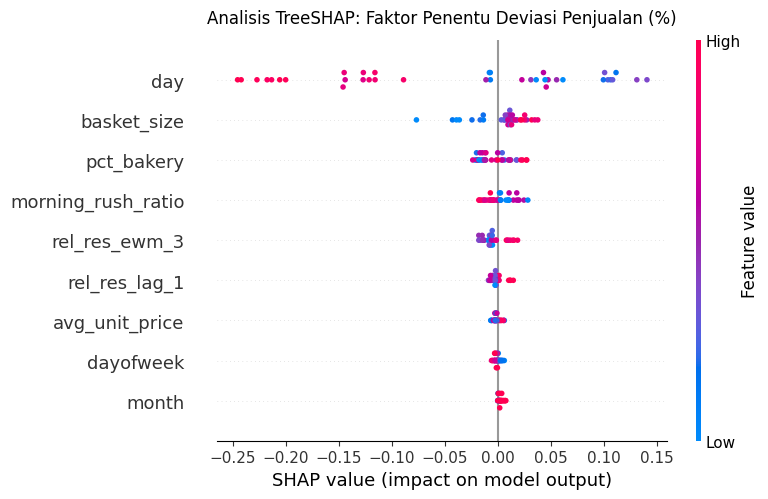

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import shap
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from quantile_forest import RandomForestQuantileRegressor

# ==============================================================================
# 1. EKSTRAKSI FITUR OPERASIONAL HARIAN (TERMASUK BASKET SIZE)
# ==============================================================================
def extract_operational_features(df_raw, location="Hell's Kitchen"):
    df_op = df_raw.copy()
    if 'store_location' in df_op.columns:
        df_op = df_op[df_op['store_location'] == location].copy()

    df_op['ds'] = pd.to_datetime(df_op['transaction_date'])
    df_op['hour'] = pd.to_datetime(df_op['transaction_time'].astype(str), format='%H:%M:%S', errors='coerce').dt.hour

    df_op['is_morning'] = np.where(df_op['hour'].between(7, 10), df_op['transaction_qty'], 0)
    df_op['qty_bakery'] = np.where(df_op['product_category'] == 'Bakery', df_op['transaction_qty'], 0)

    daily_op = df_op.groupby('ds').agg(
        total_qty=('transaction_qty', 'sum'),
        n_tx=('transaction_id', 'count'),
        morning_qty=('is_morning', 'sum'),
        bakery_qty=('qty_bakery', 'sum'),
        avg_unit_price=('unit_price', 'mean')
    ).reset_index()

    # Seluruh fitur operasional berbentuk rasio/rata-rata agar bebas pergeseran skala
    daily_op['morning_rush_ratio'] = daily_op['morning_qty'] / daily_op['total_qty']
    daily_op['pct_bakery'] = daily_op['bakery_qty'] / daily_op['total_qty']
    daily_op['basket_size'] = daily_op['total_qty'] / daily_op['n_tx']

    return daily_op[['ds', 'morning_rush_ratio', 'pct_bakery', 'basket_size', 'avg_unit_price']]

daily_op_features = extract_operational_features(df, location="Hell's Kitchen")


# ==============================================================================
# 2. PEMBUATAN FITUR & TARGET RESIDUAL RELATIF (SELARAS DENGAN MAPE & SMAPE)
# ==============================================================================
def build_relative_features(train_df, test_df, prophet_model, daily_op):
    full_df = pd.concat([train_df[['ds', 'y']], test_df[['ds', 'y']]], ignore_index=True)
    full_df['ds'] = pd.to_datetime(full_df['ds'])
    full_df = full_df.sort_values('ds').reset_index(drop=True)

    # Prediksi dasar Prophet & target residual relatif (%)
    prophet_pred = prophet_model.predict(full_df[['ds']])
    full_df['yhat_prophet'] = np.maximum(prophet_pred['yhat'].values, 1.0)
    full_df['rel_residual'] = (full_df['y'] - full_df['yhat_prophet']) / full_df['yhat_prophet']

    # 1. Fitur Kalender Utama (mengembalikan month & mempertahankan day, dayofweek)
    full_df['dayofweek'] = full_df['ds'].dt.dayofweek
    full_df['month'] = full_df['ds'].dt.month
    full_df['day'] = full_df['ds'].dt.day

    # 2. Momentum Deviasi Persentase (kemarin & rata-rata eksponensial 3 hari)
    full_df['rel_res_lag_1'] = full_df['rel_residual'].shift(1)
    full_df['rel_res_ewm_3'] = full_df['rel_residual'].shift(1).ewm(span=3, adjust=False).mean()

    # 3. Fitur Operasional Kedai (di-shift 1 hari agar tanpa data leakage)
    full_df = pd.merge(full_df, daily_op, on='ds', how='left')
    for col in ['morning_rush_ratio', 'pct_bakery', 'basket_size', 'avg_unit_price']:
        full_df[col] = full_df[col].shift(1)

    full_df = full_df.bfill()

    train_out = full_df.iloc[:len(train_df)].copy().reset_index(drop=True)
    test_out = full_df.iloc[len(train_df):].copy().reset_index(drop=True)
    return train_out, test_out

train_feat, test_feat = build_relative_features(train, test, model_baseline, daily_op_features)

feature_cols = [
    'dayofweek',
    'month',
    'day',
    'rel_res_lag_1',
    'rel_res_ewm_3',
    'pct_bakery',
    'basket_size',
    'morning_rush_ratio',
    'avg_unit_price'
]

X_train = train_feat[feature_cols]
y_train_rel_res = train_feat['rel_residual']

X_test = test_feat[feature_cols]
y_true = test_feat['y'].values


# ==============================================================================
# 3. OPTIMASI OPTUNA & PELATIHAN QRF
# ==============================================================================
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 250, step=25),
        'max_depth': trial.suggest_int('max_depth', 8, 18),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 8),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 4),
        'random_state': 42
    }

    tscv = TimeSeriesSplit(n_splits=3)
    maes = []
    for tr_idx, val_idx in tscv.split(X_train):
        qrf = RandomForestQuantileRegressor(**params)
        qrf.fit(X_train.iloc[tr_idx], y_train_rel_res.iloc[tr_idx])
        preds = qrf.predict(X_train.iloc[val_idx], quantiles=[0.5]).flatten()
        maes.append(mean_absolute_error(y_train_rel_res.iloc[val_idx], preds))
    return np.mean(maes)

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)

print("Hiperparameter QRF Terbaik:", study.best_params)

best_qrf = RandomForestQuantileRegressor(**study.best_params, random_state=42)
best_qrf.fit(X_train, y_train_rel_res)

# Prediksi kuantil 10%, 50%, 90% dan kembalikan ke skala kuantitas unit: yhat * (1 + rel_res)
pred_q = best_qrf.predict(X_test, quantiles=[0.1, 0.5, 0.9])
yhat_base_test = test_feat['yhat_prophet'].values

y_pred_lower = np.maximum(0, yhat_base_test * (1.0 + pred_q[:, 0]))
y_pred_ensemble = np.maximum(0, yhat_base_test * (1.0 + pred_q[:, 1]))
y_pred_upper = np.maximum(0, yhat_base_test * (1.0 + pred_q[:, 2]))

# Evaluasi Lengkap
mae_ens = mean_absolute_error(y_true, y_pred_ensemble)
rmse_ens = np.sqrt(mean_squared_error(y_true, y_pred_ensemble))
mape_ens = np.mean(np.abs((y_true - y_pred_ensemble) / y_true)) * 100
smape_ens = np.mean(2 * np.abs(y_pred_ensemble - y_true) / (np.abs(y_true) + np.abs(y_pred_ensemble))) * 100
r2_ens = r2_score(y_true, y_pred_ensemble)

print("\n=== HASIL EVALUASI FINAL ENSEMBLE PROPHET + QRF (RELATIVE RESIDUAL) ===")
print(f"MAE   : {mae_ens:.4f}")
print(f"RMSE  : {rmse_ens:.4f}")
print(f"MAPE  : {mape_ens:.2f}%")
print(f"SMAPE : {smape_ens:.2f}%")
print(f"R2    : {r2_ens:.4f}")


# ==============================================================================
# 4. INTERPRETASI MODEL DENGAN TREESHAP (SKALA PERSENTASE DEVIASI)
# ==============================================================================
try:
    explainer = shap.TreeExplainer(best_qrf)
    shap_values = explainer.shap_values(X_test)
except Exception:
    rf_surrogate = RandomForestRegressor(random_state=42)
    rf_surrogate.estimators_ = best_qrf.estimators_
    rf_surrogate.n_estimators = len(best_qrf.estimators_)
    rf_surrogate.n_features_in_ = X_train.shape[1]
    rf_surrogate.n_outputs_ = 1
    rf_surrogate.criterion = "squared_error"
    explainer = shap.TreeExplainer(rf_surrogate)
    shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(9, 5))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("Analisis TreeSHAP: Faktor Penentu Deviasi Penjualan (%)", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("treeshap_beeswarm_final.png", dpi=300, bbox_inches='tight')
plt.show()